In [1]:
# =========================
# 1) Imports
# =========================
import os, math, json, copy
import numpy as np
import matplotlib.pyplot as plt

from typing import Dict, Tuple, List

from sklearn.decomposition import PCA
from sklearn.model_selection import KFold
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score, mean_squared_error

import umap
import torch
from scipy.signal import butter, filtfilt, hilbert, sawtooth
from scipy.ndimage import gaussian_filter1d
from scipy.stats import circmean, ttest_rel

# Your package
from pathlib import Path
import sys

for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
    code_dir = p / "code"
    if (code_dir / "comets").exists():
        if str(code_dir) not in sys.path:
            sys.path.insert(0, str(code_dir))
        break

import comets
from comets.encoders import CEBRASKipEncoder, SkippedConvEncoderConfig
from comets.configs import ModalityConfig, SamplingConfig, TrainingConfig
from comets.heads import LinearHead

# CEBRA baseline (assume available)
import cebra

import pandas as pd


In [ ]:
# =========================
# 2) Configurations (edit)
# =========================
# --- Simulation ---
SIM_SEED        = 5

# --- Evaluation control ---
TRAIN_FRAC      = 0.7              # used if KFOLDS <= 1
KFOLDS          = 10                # set >1 to enable KFold over time-blocks
KFOLD_BLOCKS    = 10                # contiguous blocks across time
N_SEEDS         = 10                # model-fit repetitions
RIDGE_ALPHA     = 0.1
STANDARDIZE_Z   = True

# --- Quick-run switch (for sanity/style check) ---
QUICK_EPOCHS    = 10             # CoMETs epochs for dry run
FULL_EPOCHS     = 100               # CoMETs epochs for full run

# --- CoMETs hyperparams ---
WINLEN_A        = 8
WINLEN_B        = 8
EMB_A_DIM       = 32
EMB_B_DIM       = 16
BATCH_SIZE      = 256
POS_OFFSET      = 5
NEG_MASK_DIST   = 16
LR              = 1e-3
TEMPERATURE     = 1.0

ALPHA_CROSS     = 0.05 # weight cross vs within
BETA_AB         = 0.5  # balance A vs B (default equal)

PROJ_DIM        = 8

# --- CEBRA hyperparams ---
CEBRA_DIM_A     = 32
CEBRA_DIM_B     = 16
CEBRA_ITERS     = 100
CEBRA_TEMP      = 1.0

# --- Models and shuffles to run in the full sweep ---
MODELS = ("CoMETs", "PCA", "UMAP", "CEBRA")
SHUFFLES_BY_MODEL = {
    "PCA":   ["real", "channel_indep"],
    "UMAP":  ["real", "channel_indep"],
    "CEBRA": ["real", "channel_indep", "global"],
    "CoMETs": ["real", "channel_indep", "global", "lfp_only"],
}

# plotting
plt.rcParams["figure.dpi"] = 110
np.set_printoptions(suppress=True, precision=4)


In [3]:
# =========================
# 3) CONFIGURATION
# =========================
# --- Simulation ---
FS              = 250
T_SEC           = 15
MOVE_MODE       = "biased_rw"      # "constant" | "nonstationary" | "biased_rw"

# --- Cell counts ---
n_place         = 15
n_multipeak     = 10
n_noisy         = 40
n_hd            = 5
n_cells_total   = n_place + n_multipeak + n_noisy + n_hd
ALLOW_SEGMENTS = [(-1.0, -0.55), (-0.4, 0.3), (0.45, 0.85)] # (-1,1)
# ALLOW_SEGMENTS = None

# --- LFP channels ---
n_lfp           = 16

# --- Noise and coupling controls ---
NOISE_WHITE_STD = 0.30     # additive white noise
NOISE_PINK_STD  = 0.25     # low-freq pink drift
PSP_GAIN        = 0.15     # spike→LFP coupling
PHASE_POS_GAIN  = 0.5     # spatial phase modulation
AMP_POS_GAIN    = 0.00     # amplitude-position modulation
CH_PHASE_JITTER_DEG = 30.0

# --- Theta + amplitude envelopes ---
THETA_F0 = 8.0
THETA_WOBBLE1_HZ, THETA_WOBBLE1_AMP = 0.02, 0.4
THETA_WOBBLE2_HZ, THETA_WOBBLE2_AMP = 0.006, 0.2
AMP_BASE, AMP_SPEED_GAIN, AMP_DRIFT_GAIN, AMP_DRIFT_FREQ = 0.60, 0.35, 0.15, 0.015

# --- Place & multi-peak tuning strength (to modulate difficulty) ---
PF_WIDTH_RANGE = (0.10, 0.22)
PF_PEAK_HZ     = (6.0, 12.0)
PF_BASE_HZ     = (0.1, 0.4)
PF_KAPPA       = (2.0, 6.0)
MP_NUM_RANGE   = (2, 4)
MP_WIDTH_RANGE = (0.12, 0.28)
MP_AMP_RANGE   = (3.0, 7.0)
MP_KAPPA       = (1.0, 3.0)

# --- Noise cell parameters ---
NOISY_KAPPA    = (0.0, 1.0)
NOISY_RW_STD   = 0.04


print(f"Sim seed={SIM_SEED}, total cells={n_cells_total}, LFP={n_lfp}")


Sim seed=5, total cells=70, LFP=16


In [4]:
# =========================
# 3) Utilities
# =========================
def set_all_seeds(seed: int):
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

def blocked_split_idx(T: int, train_frac: float):
    n_train = int(T * train_frac)
    idx = np.arange(T)
    return idx[:n_train], idx[n_train:]

def make_splits(T, train_frac=0.7, kfolds=0, k_blocks=5):
    if kfolds and kfolds > 1:
        block_len = T // k_blocks
        blocks = [np.arange(i*block_len, (i+1)*block_len if i<k_blocks-1 else T) for i in range(k_blocks)]
        kf = KFold(n_splits=kfolds, shuffle=False)
        splits = []
        for trb, teb in kf.split(blocks):
            tr_idx = np.concatenate([blocks[i] for i in trb])
            te_idx = np.concatenate([blocks[i] for i in teb])
            splits.append((tr_idx, te_idx))
        return splits
    else:
        tr, te = blocked_split_idx(T, train_frac)
        return [(tr, te)]

def standardize(X: np.ndarray) -> np.ndarray:
    mu = X.mean(axis=0, keepdims=True)
    sd = X.std(axis=0, keepdims=True) + 1e-9
    return (X - mu) / sd

def rmse(y, yhat):
    return np.sqrt(mean_squared_error(y, yhat))

def ridge_decode(Ztr, ytr, Zte, alpha=0.1):
    model = Ridge(alpha=alpha)
    model.fit(Ztr, ytr)
    yhat = model.predict(Zte)
    return yhat, model


In [5]:
# =========================
# SIMULATION
# =========================
set_all_seeds(SIM_SEED)
rng = np.random.default_rng(SIM_SEED)
t = np.arange(0, T_SEC, 1 / FS)
N = t.size

# ===== Movement trajectory =====
def movement_constant_linear(t, fs, f_traversal=0.08):
    from scipy.signal import sawtooth
    x = sawtooth(2*np.pi*f_traversal*t, width=0.5)
    v = np.gradient(x) * fs
    v_norm = np.abs(v)/(np.abs(v).max()+1e-9)
    return x.astype(np.float32), v.astype(np.float32), v_norm.astype(np.float32)

def movement_nonstationary(t, fs):
    base, a1, f1, phi1, a2, f2, phi2 = 0.22, 0.07, 0.010, 0.7, 0.03, 0.045, 1.1
    speed = base + a1*np.sin(2*np.pi*f1*t+phi1) + a2*np.sin(2*np.pi*f2*t+phi2)
    speed = np.clip(speed, 0.05, None)
    phase = 2*np.pi * np.cumsum(speed)/fs
    x = np.sin(phase); v = np.gradient(x)*fs
    v_norm = np.abs(v)/(np.abs(v).max()+1e-9)
    return x.astype(np.float32), v.astype(np.float32), v_norm.astype(np.float32)

def movement_discrete(t, fs, step_size=0.02, decision_interval=15, turn_prob_scale=5.5, pause_prob_base=0.05, boundary=1.0):
    x = np.zeros(N, dtype=np.float32); v = np.zeros(N, dtype=np.float32); direction = 1.0
    for n in range(1, N):
        if n % decision_interval == 0:
            d = min((boundary - x[n-1]) / boundary, (boundary + x[n-1]) / boundary)
            p_turn  = np.clip(np.exp(-turn_prob_scale*d), 0, 1)
            p_pause = np.clip(pause_prob_base + 0.1*(1-d), 0, 0.3)
            p_fwd   = np.clip(1 - (p_turn+p_pause), 0, 1)
            if abs(x[n-1]) >= 0.99*boundary:
                p_turn, p_pause, p_fwd = 0.20, 0.70, 0.0
            probs = np.array([p_fwd, p_turn, p_pause]); probs /= probs.sum()
            action = rng.choice(["forward","turn","pause"], p=probs)
            if action=="turn": direction = -direction if direction!=0 else rng.choice([-1,1])
            elif action=="pause": direction = 0.0
            elif direction==0: direction = rng.choice([-1.0,1.0])
        x[n] = x[n-1] + direction * step_size
        if x[n] > boundary: x[n] = boundary; direction = -1.0
        if x[n] < -boundary: x[n] = -boundary; direction = 1.0
        v[n] = direction * step_size * fs
    from scipy.ndimage import gaussian_filter1d
    x_s = gaussian_filter1d(x, sigma=1.0)
    v_an = np.gradient(x_s)*fs
    v_norm = np.abs(v_an)/(np.max(np.abs(v_an))+1e-9)
    return x_s, v_an, v_norm

if MOVE_MODE == "constant":     x, v_animal, v_norm = movement_constant_linear(t, FS)
elif MOVE_MODE == "nonstationary": x, v_animal, v_norm = movement_nonstationary(t, FS)
elif MOVE_MODE ==  "biased_rw":   x, v_animal, v_norm = movement_discrete(t, FS)

# ===== Theta phase + amplitude envelope =====
f_theta = THETA_F0 + THETA_WOBBLE1_AMP*np.sin(2*np.pi*THETA_WOBBLE1_HZ*t) + \
           THETA_WOBBLE2_AMP*np.sin(2*np.pi*THETA_WOBBLE2_HZ*t + 0.9)
phi_theta = 2*np.pi*np.cumsum(f_theta)/FS
A_env = np.clip(AMP_BASE + AMP_SPEED_GAIN*v_norm + AMP_DRIFT_GAIN*np.sin(2*np.pi*AMP_DRIFT_FREQ*t + 0.3), 0.1, 1.5)

# ===== Spiking population =====
rates  = np.zeros((n_cells_total, N), dtype=np.float32)
labels = []

def gauss_field(xx, mu, sig): return np.exp(-0.5*((xx - mu)/sig)**2)

# -----------------------------
# Helpers
# -----------------------------
def allowed_mask(pos, segments):
    if segments is None:
        return np.ones_like(pos, dtype=float)
    m = np.zeros_like(pos, dtype=float)
    for a,b in segments:
        m += ((pos>=a) & (pos<=b)).astype(float)
    return np.clip(m, 0, 1)

def sample_center_from_allowed(rng, segments):
    if segments is None:
        return rng.uniform(-0.9, 0.9)
    seg = segments[rng.integers(len(segments))]
    return rng.uniform(seg[0], seg[1])

# Keep your mask code the same:
M_allow = allowed_mask(x, ALLOW_SEGMENTS)

# --- Place cells
for i in range(n_place):
    mu  = sample_center_from_allowed(rng, ALLOW_SEGMENTS)
    sig = rng.uniform(*PF_WIDTH_RANGE)
    pk  = rng.uniform(*PF_PEAK_HZ)
    b   = rng.uniform(*PF_BASE_HZ)
    kap = rng.uniform(*PF_KAPPA)
    field = np.exp(-0.5*((x - mu)/sig)**2) * (M_allow if ALLOW_SEGMENTS else 1.0)
    phase_pref = (np.pi/2) - np.pi*((x - mu)/sig)
    phase_gain = np.exp(kap * np.cos(phi_theta - phase_pref))
    rates[i]   = (b + pk * field) * phase_gain
    labels.append("place")

# --- Multi-peak cells
off = n_place
for i in range(off, off + n_multipeak):
    n_bumps = rng.integers(*MP_NUM_RANGE)
    mus  = [sample_center_from_allowed(rng, ALLOW_SEGMENTS) for _ in range(n_bumps)]
    sigs = rng.uniform(*MP_WIDTH_RANGE, size=n_bumps)
    amps = rng.uniform(*MP_AMP_RANGE, size=n_bumps)
    field = np.zeros(N)
    for m,s,a in zip(mus,sigs,amps):
        field += a*np.exp(-0.5*((x - m)/s)**2) * (M_allow if ALLOW_SEGMENTS else 1.0)
    kap  = rng.uniform(*MP_KAPPA)
    pref = rng.uniform(-np.pi, np.pi)
    rates[i] = (rng.uniform(0.05,0.3) + field) * np.exp(kap * np.cos(phi_theta - pref))
    labels.append("multi-peak")

# Noisy
off2 = off + n_multipeak
for i in range(off2, off2 + n_noisy):
    rw = np.cumsum(rng.normal(0, NOISY_RW_STD, size=N))
    rw = (rw - rw.min()) / (rw.max() - rw.min() + 1e-9)
    base = rng.uniform(0.2, 1.0); amp = rng.uniform(2.0, 5.0)
    kap  = rng.uniform(*NOISY_KAPPA); pref = rng.uniform(-np.pi, np.pi)
    rates[i] = (base + amp*rw) * np.exp(kap * np.cos(phi_theta - pref))
    labels.append("noisy")

# Head-direction
off3 = off2 + n_noisy
dir_signal = np.sign(v_animal); dir_signal[dir_signal == 0] = 1
dir_angle  = np.where(dir_signal > 0, np.pi/2, -np.pi/2) + rng.normal(0, 0.15, size=N)
for i in range(off3, off3 + n_hd):
    k_dir = rng.uniform(2.0, 6.0); pref = rng.uniform(-np.pi, np.pi)
    base  = rng.uniform(0.2, 1.0); pk = rng.uniform(8.0, 15.0)
    kap_theta = rng.uniform(1.0, 3.0); theta_pref = rng.uniform(-np.pi, np.pi)
    dir_term = np.exp(k_dir * np.cos(dir_angle - pref)); dir_term /= dir_term.max() + 1e-9
    rates[i] = (base + pk*dir_term) * np.exp(kap_theta * np.cos(phi_theta - theta_pref))
    labels.append("hd")

# Sample spikes and smooth
p_spike = rates / FS
spikes  = rng.random((n_cells_total, N)) < p_spike
A_real  = gaussian_filter1d(spikes.astype(float), sigma=2, axis=1).T

# ===== LFP synthesis =====
phase_jitter = np.deg2rad(CH_PHASE_JITTER_DEG)
ch_phase = rng.uniform(-phase_jitter, phase_jitter, size=n_lfp)
x_norm = (x - x.min()) / (x.max() - x.min() + 1e-9)
phase_pos_jitter = np.zeros((N, n_lfp))
for ch in range(n_lfp):
    a1, b1, a2, b2 = rng.normal(0,1,4)
    phase_pos_jitter[:, ch] = PHASE_POS_GAIN * (
        0.6*np.sin(2*np.pi*x_norm)*a1 + 0.4*np.cos(4*np.pi*x_norm)*b1
        + 0.3*np.sin(6*np.pi*x_norm)*a2 + 0.2*np.cos(8*np.pi*x_norm)*b2
    )
lfp_theta = (A_env[:, None]) * np.sin(phi_theta[:, None] + ch_phase[None, :] + phase_pos_jitter)
# PSP coupling
kern_len = max(3, int(40 * FS / 1000) | 1)
win = np.hanning(kern_len); win /= (win.sum() + 1e-9)
psp = np.zeros((N, n_lfp))
assign = rng.integers(0, n_lfp, size=n_cells_total)
for i in range(n_cells_total):
    s = spikes[i].astype(float)
    conv = np.convolve(s, win, mode='same')
    psp[:, assign[i]] += PSP_GAIN * conv
# Add noise
white = rng.normal(0, NOISE_WHITE_STD, size=(N, n_lfp))
pink  = np.cumsum(rng.normal(0, NOISE_WHITE_STD, size=(N, n_lfp)), axis=0)
pink  = (pink - pink.mean(0)) / (pink.std(0)+1e-9) * NOISE_PINK_STD
B_real = (lfp_theta + psp + white + pink).astype(np.float32)

# Target variable
position_real = x.astype(np.float32)
META = dict(fs=FS, labels=np.array(labels), phi_theta=phi_theta.astype(np.float32))
T = len(position_real)
print(f"A_real {A_real.shape}, B_real {B_real.shape}, position {position_real.shape}")


A_real (3750, 70), B_real (3750, 16), position (3750,)


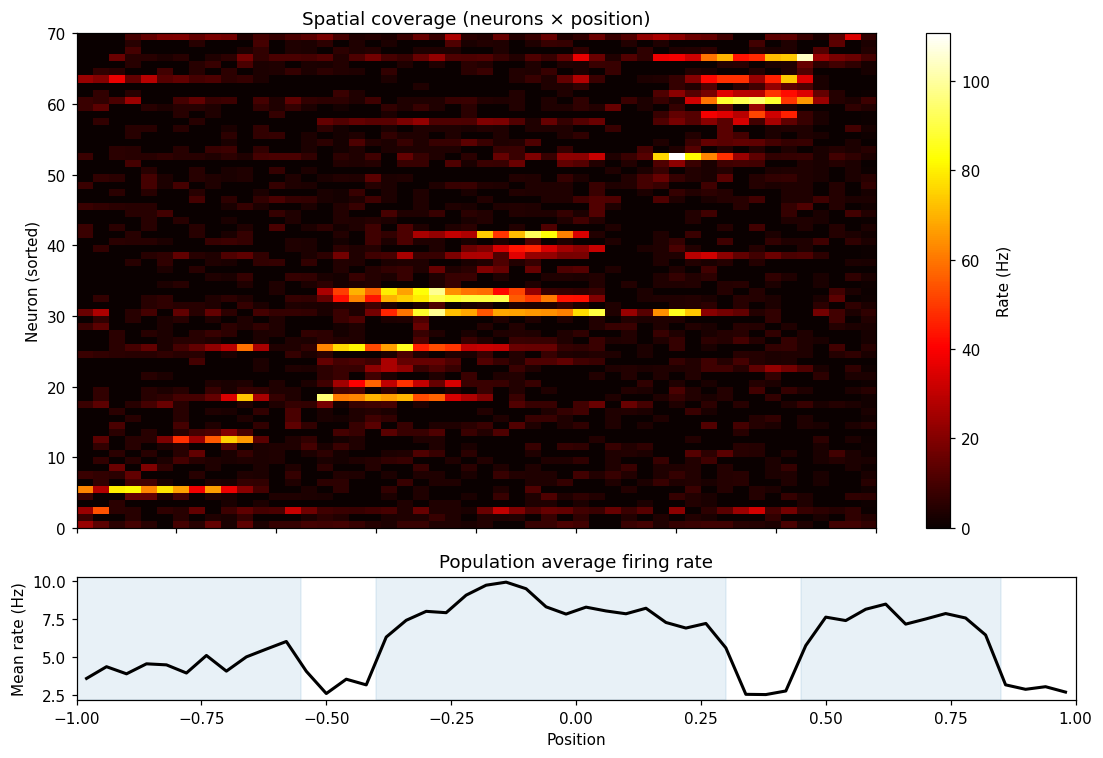

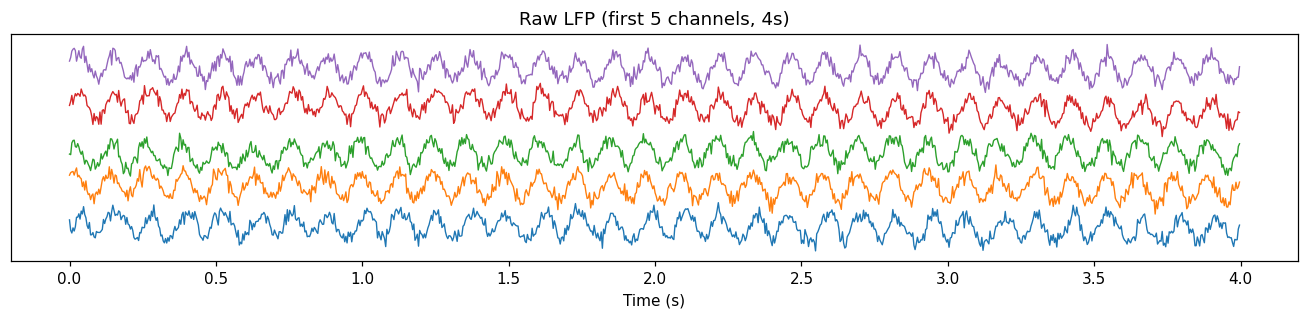

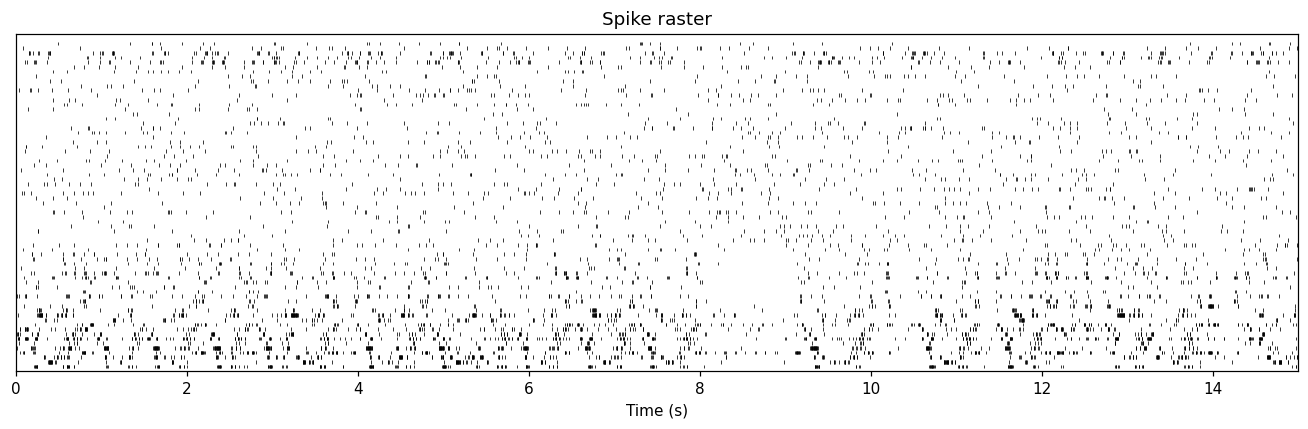

In [6]:

# --- Coverage plotting
COVERAGE_N_BINS = 50
# -----------------------------
# 3) Spatial coverage heatmap
# -----------------------------
n_bins = COVERAGE_N_BINS
edges  = np.linspace(-1, 1, n_bins+1)
cent   = 0.5*(edges[1:] + edges[:-1])
pos_bins_all = np.clip(np.digitize(x, edges)-1, 0, n_bins-1)
occ_counts = np.bincount(pos_bins_all, minlength=n_bins)
occ_time   = occ_counts / FS + 1e-9
coverage = np.zeros((n_cells_total, n_bins), dtype=float)
for i in range(n_cells_total):
    pos_bins = np.clip(np.digitize(x, edges)-1, 0, n_bins-1)
    counts = np.bincount(pos_bins[spikes[i]], minlength=n_bins)
    coverage[i] = counts / occ_time
peak_pos = cent[np.argmax(coverage, axis=1)]
order = np.argsort(peak_pos)
# -----------------------------
# Population coverage heatmap + mean firing rate
# -----------------------------
mean_rate = coverage.mean(axis=0)

fig, ax = plt.subplots(2, 1, figsize=(10, 7), sharex=True,
                       gridspec_kw={'height_ratios':[4,1]})

im = ax[0].imshow(coverage[order], aspect='auto', origin='lower',
                  extent=[-1,1,0,n_cells_total],
                  interpolation='nearest', cmap='hot')
ax[0].set_title("Spatial coverage (neurons × position)")
ax[0].set_ylabel("Neuron (sorted)")
plt.colorbar(im, ax=ax[0], label="Rate (Hz)")

ax[1].plot(cent, mean_rate, color='black', lw=2)
ax[1].set_xlabel("Position")
ax[1].set_ylabel("Mean rate (Hz)")
ax[1].set_title("Population average firing rate")

if ALLOW_SEGMENTS is not None:
    for seg in ALLOW_SEGMENTS:
        ax[1].axvspan(seg[0], seg[1], color='tab:blue', alpha=0.1)
plt.tight_layout(); plt.show()
# -----------------------------
# LFP strip plot (first few channels)
# -----------------------------
sec = 4
t_idx = slice(0, sec*FS)
n_show = min(5, n_lfp)
fig, ax = plt.subplots(figsize=(12,3))
offset = 3.0
for k in range(n_show):
    ax.plot(t[t_idx], B_real[t_idx, k] + k*offset, lw=0.9)
ax.set_title(f"Raw LFP (first {n_show} channels, {sec}s)")
ax.set_xlabel("Time (s)")
ax.set_yticks([])
plt.tight_layout(); plt.show()

# -----------------------------
# Spike raster
# -----------------------------
fig, ax = plt.subplots(figsize=(12,4))
spike_times = [np.where(spikes[i])[0]/FS for i in range(n_cells_total)]
ax.eventplot(spike_times, colors='k', lineoffsets=np.arange(n_cells_total),
             linelengths=0.8, lw=0.5)
ax.set_xlim(0, T_SEC); ax.set_ylim(-1, n_cells_total+1)
ax.set_title("Spike raster")
ax.set_xlabel("Time (s)"); ax.set_yticks([])
plt.tight_layout(); plt.show()

In [7]:
# =========================
# 5) Model runners + shuffles
# =========================
def run_pca(X, n_components=16):  return PCA(n_components=n_components).fit_transform(X)

def run_umap(X, n_components=16, n_neighbors=15, min_dist=0.1, seed=0):
    reducer = umap.UMAP(n_components=n_components, n_neighbors=n_neighbors, min_dist=min_dist, random_state=seed)
    return reducer.fit_transform(X)

def run_cebra(X, out_dim=16, iters=500, temp=1.0, batch_size=256):
    m = cebra.CEBRA(model_architecture="offset10-model",
                    output_dimension=out_dim,
                    max_iterations=iters,
                    batch_size=batch_size,
                    temperature=temp,
                    verbose=False)
    return m.fit_transform(X)

def run_comets(A, B, epochs, seed):
    set_all_seeds(seed)
    modA = ModalityConfig(encoder_cls=CEBRASKipEncoder,
                          encoder_cfg=SkippedConvEncoderConfig(in_channels=A.shape[1], emb_dim=EMB_A_DIM),
                          win_len=WINLEN_A)
    modB = ModalityConfig(encoder_cls=CEBRASKipEncoder,
                          encoder_cfg=SkippedConvEncoderConfig(in_channels=B.shape[1], emb_dim=EMB_B_DIM),
                          win_len=WINLEN_B)
    sampling = SamplingConfig(batch_size=BATCH_SIZE, pos_offset=POS_OFFSET, negative_mask_dist=NEG_MASK_DIST)
    train_cfg = TrainingConfig(epochs=epochs, lr=LR, temperature=TEMPERATURE, proj_dim=PROJ_DIM,
                               alpha_cross=ALPHA_CROSS, beta=BETA_AB, head_cls=LinearHead)
    model = comets.train(A, modA, B, modB, sampling, train_cfg)
    return model.embedA(A), model.embedB(B)

def pca3(Z):
    Z = np.asarray(Z)
    if Z.shape[1] > 3:  Z = PCA(n_components=3).fit_transform(Z)
    if Z.shape[1] < 3:  Z = np.pad(Z, ((0,0),(0, 3-Z.shape[1])), mode="constant")
    return Z 
def decode_from_Z(Z, y, tr_idx, te_idx):
    Ztr, Zte = Z[tr_idx], Z[te_idx]
    ytr, yte = y[tr_idx], y[te_idx]
    if STANDARDIZE_Z: Ztr, Zte = standardize(Ztr), standardize(Zte)
    yhat, _ = ridge_decode(Ztr, ytr, Zte, alpha=RIDGE_ALPHA)
    return r2_score(yte, yhat), rmse(yte, yhat), yhat, yte




Training: 100%|██████████| 10/10 [00:03<00:00,  3.16it/s, total=4.8331, within=4.7988, cross=5.4843, lr=0.00e+00]


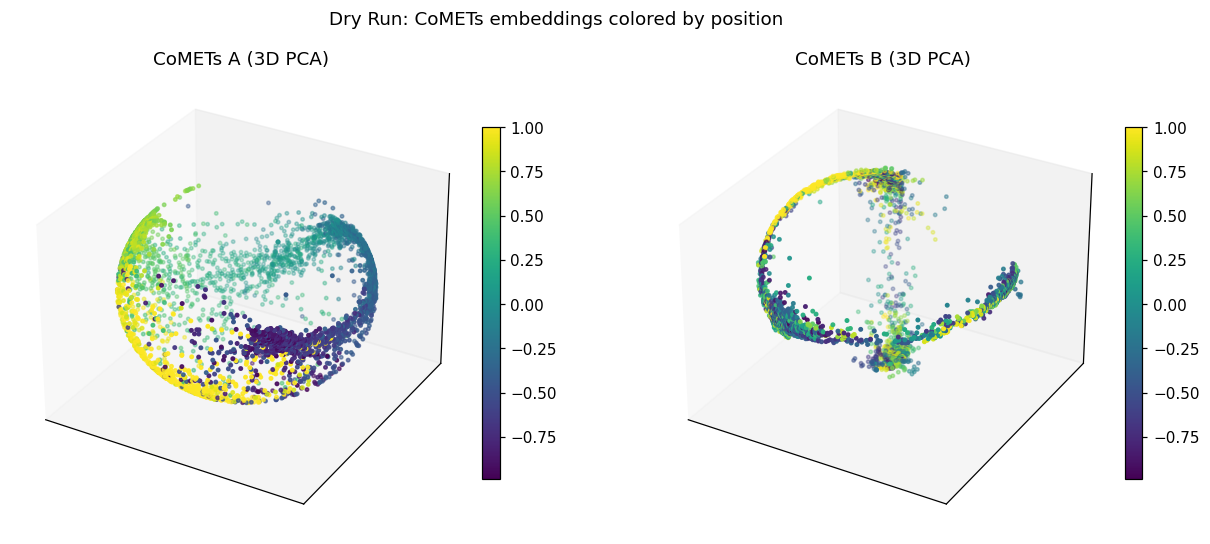

[Dry] CoMETs A: R²=0.486, RMSE=0.421 | CoMETs B: R²=-0.205, RMSE=0.644


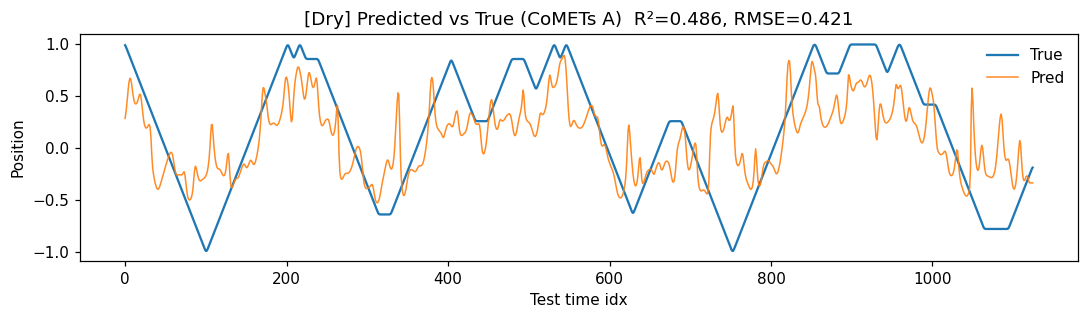

In [8]:
# =========================
# 6) DRY RUN: one CoMET
# =========================
DRY_SEED = SIM_SEED
SPLITS_DRY = make_splits(T, TRAIN_FRAC, kfolds=0)
tr_idx, te_idx = SPLITS_DRY[0]

# Train a tiny CoMETs for a quick look
ZA_dry, ZB_dry = run_comets(A_real, B_real, epochs=QUICK_EPOCHS, seed=DRY_SEED)

# --- Embedding visualization (3D PCA projection colored by position) ---
fig = plt.figure(figsize=(12,5))
ax = fig.add_subplot(1,2,1, projection="3d")
Zr = pca3(ZA_dry)
p  = ax.scatter(Zr[:,0], Zr[:,1], Zr[:,2], c=position_real, s=5)
ax.set_title("CoMETs A (3D PCA)"); ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])
fig.colorbar(p, ax=ax, fraction=0.03, pad=0.02)

ax = fig.add_subplot(1,2,2, projection="3d")
Zr = pca3(ZB_dry)
p  = ax.scatter(Zr[:,0], Zr[:,1], Zr[:,2], c=position_real, s=5)
ax.set_title("CoMETs B (3D PCA)"); ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])
fig.colorbar(p, ax=ax, fraction=0.03, pad=0.02)
plt.suptitle("Dry Run: CoMETs embeddings colored by position"); plt.tight_layout(); plt.show()

# --- Decoding (R², RMSE) & predicted vs true on test segment ---
r2A, eA, yhatA, yteA = decode_from_Z(ZA_dry, position_real, tr_idx, te_idx)
r2B, eB, yhatB, yteB = decode_from_Z(ZB_dry, position_real, tr_idx, te_idx)
print(f"[Dry] CoMETs A: R²={r2A:.3f}, RMSE={eA:.3f} | CoMETs B: R²={r2B:.3f}, RMSE={eB:.3f}")

Nshow = min(2500, len(yteA))
plt.figure(figsize=(10,3))
plt.plot(yteA[:Nshow], label="True", linewidth=1.5)
plt.plot(yhatA[:Nshow], label="Pred", linewidth=1.0, alpha=0.9)
plt.title(f"[Dry] Predicted vs True (CoMETs A)  R²={r2A:.3f}, RMSE={eA:.3f}")
plt.xlabel("Test time idx"); plt.ylabel("Position"); plt.legend(frameon=False)
plt.tight_layout(); plt.show()


In [9]:
# --- Shuffles ---
def shuffle_channel_indep(X, rng):
    Xs = X.copy()
    for j in range(Xs.shape[1]):
        perm = rng.permutation(Xs.shape[0])
        Xs[:, j] = Xs[perm, j]
    return Xs

def apply_shuffle(A, B, position, mode, rng):
    if mode == "real":
        return A, B, position
    elif mode == "channel_indep":
        return shuffle_channel_indep(A, rng), shuffle_channel_indep(B, rng), position
    elif mode == "global":
        perm = rng.permutation(A.shape[0])
        return A[perm], B[perm], position          # break neural-behavior alignment
    elif mode == "lfp_only":
        return A, shuffle_channel_indep(B, rng), position
    else:
        raise ValueError(f"Unknown shuffle mode: {mode}")

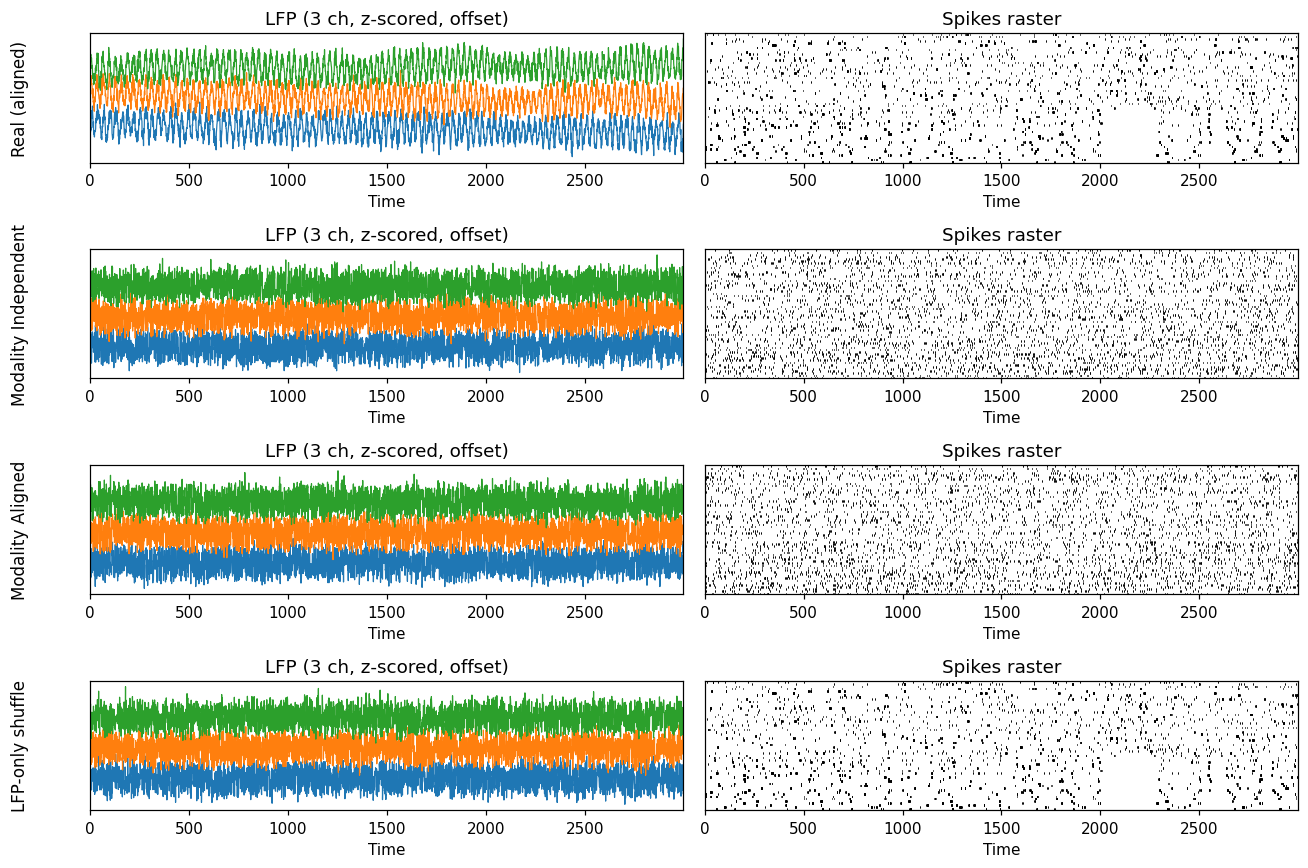

In [10]:
# =========================
# Shuffle sanity check: LFP traces + spike raster per condition
# =========================

# --- uses your functions exactly as defined above ---
# def shuffle_channel_indep(X, rng): ...
# def apply_shuffle(A, B, position, mode, rng): ...

rng = np.random.default_rng(123)

modes = ["real", "channel_indep", "global", "lfp_only"]

# --- config for the plot ---
N_PLOT = 3000           # how manAy time-points to show
LFP_CH = [0, 1, 2]      # which LFP channels to plot (change if neeAed)
N_RASTER = 60           # how many neurons to show in raster (top rows)
linew = 0.8

def _make_raster_from_A(A_slice):
    """Fallback raster from smoothed rates A by thresholding per-neuron."""
    # per-neuron threshold at high percentile to get sparse events
    thr = np.percentile(A_slice, 97, axis=0, keepdims=True)
    return (A_slice > thr).astype(bool)

def _plot_lfp_block(ax, B, t0=0, n=N_PLOT, ch=LFP_CH, offset=3.0):
    """Plot several LFP channels with vertical offset."""
    T = min(n, B.shape[0]-t0)
    t = np.arange(T)
    for k, j in enumerate(ch):
        y = B[t0:t0+T, j]
        # z-score for comparable amplitude
        y = (y - y.mean()) / (y.std() + 1e-9)
        ax.plot(t, y + k*offset, lw=linew)
    ax.set_xlim(0, T-1)
    ax.set_yticks([])
    ax.set_xlabel("Time")
    ax.set_title("LFP (3 ch, z-scored, offset)")

def _plot_raster_block(ax, A, t0=0, n=N_PLOT, n_cells=N_RASTER):
    """Plot spike raster directly from A (no global spikes)."""
    T = min(n, A.shape[0]-t0)
    # Always derive events from A itself
    S = _make_raster_from_A(A[t0:t0+T, :n_cells]).T  # shape (n_cells, T)

    for r in range(S.shape[0]):
        ts = np.flatnonzero(S[r])
        if ts.size:
            ax.vlines(ts, r, r+0.8, colors="k", lw=0.5)
    ax.set_ylim(0, S.shape[0])
    ax.set_xlim(0, T-1)
    ax.set_yticks([])
    ax.set_xlabel("Time")
    ax.set_title("Spikes raster")

    # draw raster
    rows, cols = S.shape
    for r in range(rows):
        ts = np.flatnonzero(S[r])
        if ts.size:
            ax.vlines(ts, r, r+0.8, colors="k", lw=0.5)
    ax.set_ylim(0, rows)
    ax.set_xlim(0, T-1)
    ax.set_yticks([])
    ax.set_xlabel("Time")
    ax.set_title("Spikes raster")

fig, axes = plt.subplots(len(modes), 2, figsize=(12, 8), sharex=False, sharey=False)
if len(modes) == 1:
    axes = np.array([axes])

for i, mode in enumerate(modes):
    A_s, B_s, pos_s = apply_shuffle(A_real, B_real, position_real, mode, rng)

    # Left: LFP snippet
    _plot_lfp_block(axes[i, 0], B_s, t0=0, n=N_PLOT, ch=LFP_CH)
    # Right: spike raster (first N_RASTER units)
    _plot_raster_block(axes[i, 1], A_s)

    # Row title explaining the shuffle
    nice_name = {
        "real": "Real (aligned)",
        "channel_indep": "Modality Independent",
        "global": "Modality Aligned",
        "lfp_only": "LFP-only shuffle",
    }[mode]
    axes[i, 0].set_ylabel(nice_name, rotation=90, labelpad=40, fontsize=11)

# tidy
for ax in axes.ravel():
    ax.grid(axis='y', alpha=0.15, linestyle='--')
plt.tight_layout()
plt.show()


Training: 100%|██████████| 10/10 [00:02<00:00,  3.51it/s, total=5.1427, within=5.1222, cross=5.5321, lr=0.00e+00]


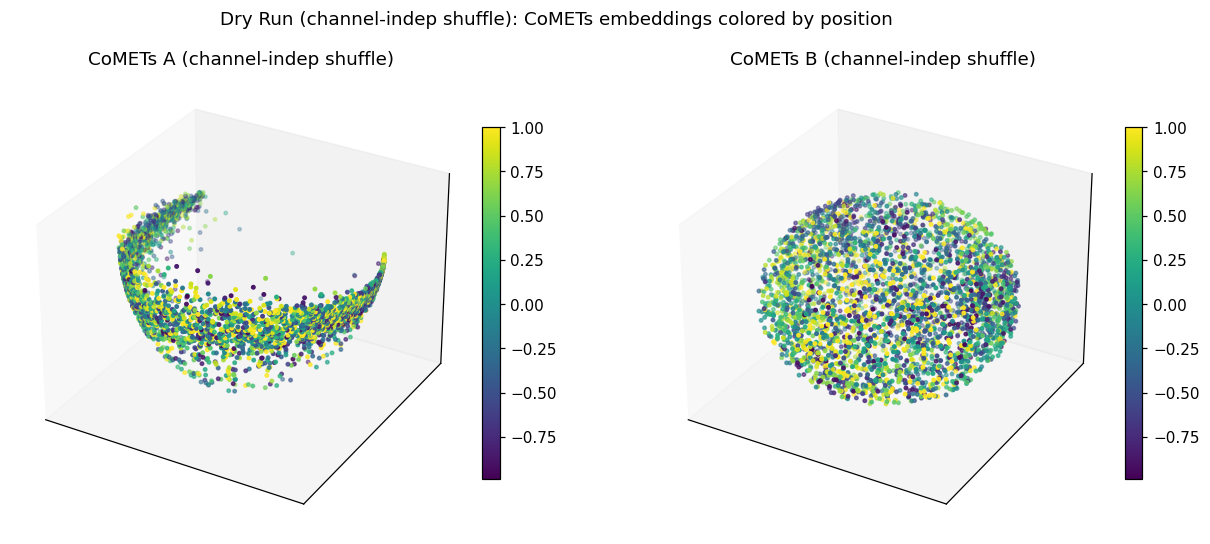

[Dry Shuffle] CoMETs A: R²=-0.105, RMSE=0.617 | CoMETs B: R²=-0.044, RMSE=0.600


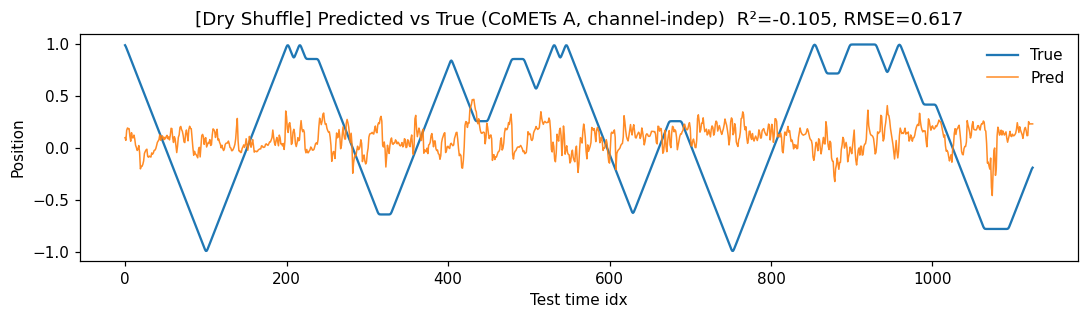

In [11]:
# =========================
# 6) DRY RUN: one CoMET (channel-independent shuffle)
# =========================
DRY_SEED = SIM_SEED
SPLITS_DRY = make_splits(T, TRAIN_FRAC, kfolds=0)
tr_idx, te_idx = SPLITS_DRY[0]

# --- Apply channel-independent shuffle ---
rng = np.random.default_rng(DRY_SEED)
A_shuf, B_shuf, pos_shuf = apply_shuffle(A_real, B_real, position_real, "channel_indep", rng)

# Train a tiny CoMETs on shuffled data for a quick look
ZA_dry, ZB_dry = run_comets(A_shuf, B_shuf, epochs=QUICK_EPOCHS, seed=DRY_SEED)

# --- Embedding visualization (3D PCA projection colored by position) ---
fig = plt.figure(figsize=(12,5))
ax = fig.add_subplot(1,2,1, projection="3d")
Zr = pca3(ZA_dry)
p  = ax.scatter(Zr[:,0], Zr[:,1], Zr[:,2], c=position_real, s=5)
ax.set_title("CoMETs A (channel-indep shuffle)"); ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])
fig.colorbar(p, ax=ax, fraction=0.03, pad=0.02)

ax = fig.add_subplot(1,2,2, projection="3d")
Zr = pca3(ZB_dry)
p  = ax.scatter(Zr[:,0], Zr[:,1], Zr[:,2], c=position_real, s=5)
ax.set_title("CoMETs B (channel-indep shuffle)"); ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])
fig.colorbar(p, ax=ax, fraction=0.03, pad=0.02)
plt.suptitle("Dry Run (channel-indep shuffle): CoMETs embeddings colored by position")
plt.tight_layout(); plt.show()

# --- Decoding (R², RMSE) & predicted vs true on test segment ---
r2A, eA, yhatA, yteA = decode_from_Z(ZA_dry, pos_shuf, tr_idx, te_idx)
r2B, eB, yhatB, yteB = decode_from_Z(ZB_dry, pos_shuf, tr_idx, te_idx)
print(f"[Dry Shuffle] CoMETs A: R²={r2A:.3f}, RMSE={eA:.3f} | CoMETs B: R²={r2B:.3f}, RMSE={eB:.3f}")

# --- Plot predicted vs true on test segment (spike view) ---
Nshow = min(2500, len(yteA))
plt.figure(figsize=(10,3))
plt.plot(yteA[:Nshow], label="True", linewidth=1.5)
plt.plot(yhatA[:Nshow], label="Pred", linewidth=1.0, alpha=0.9)
plt.title(f"[Dry Shuffle] Predicted vs True (CoMETs A, channel-indep)  R²={r2A:.3f}, RMSE={eA:.3f}")
plt.xlabel("Test time idx"); plt.ylabel("Position"); plt.legend(frameon=False)
plt.tight_layout(); plt.show()


In [ ]:

RESULTS = []          # all decoding results
EMB_SAMPLES = {}      # 3D embeddings for visualization
TRAJ_EXAMPLE = {}     # full predicted trajectories (real + indep shuffle)

SPLITS = make_splits(T, TRAIN_FRAC, kfolds=KFOLDS, k_blocks=KFOLD_BLOCKS)
print(f"Full run started: {len(SPLITS)} fold(s), {N_SEEDS} seed(s).")
print("=" * 60)

for seed in range(N_SEEDS):
    rng = np.random.default_rng(seed)
    print(f"\n=== Seed {seed} ===")

    for shuffle_mode in ["real", "channel_indep", "global", "lfp_only"]:
        print(f"\n→ Training embeddings for shuffle='{shuffle_mode}'")

        # ------------------------------------------------------------
        # 1) Apply shuffle to neural data
        # ------------------------------------------------------------
        A_s, B_s, pos_s = apply_shuffle(A_real, B_real, position_real, shuffle_mode, rng)

        # ------------------------------------------------------------
        # 2) Train embeddings once per (seed, shuffle)
        # ------------------------------------------------------------
        ALL_EMBEDDINGS = {}
        for model_name in MODELS:
            print(f"  Training {model_name} ...")

            if model_name == "PCA":
                Z_A = run_pca(A_s, n_components=3)
                Z_B = run_pca(B_s, n_components=3)

            elif model_name == "UMAP":
                Z_A = run_umap(A_s, n_components=3, seed=seed)
                Z_B = run_umap(B_s, n_components=3, seed=seed)

            elif model_name == "CEBRA":
                Z_A = run_cebra(A_s, out_dim=CEBRA_DIM_A,
                                iters=CEBRA_ITERS, temp=CEBRA_TEMP,
                                batch_size=BATCH_SIZE)
                Z_B = run_cebra(B_s, out_dim=CEBRA_DIM_B,
                                iters=CEBRA_ITERS, temp=CEBRA_TEMP,
                                batch_size=BATCH_SIZE)

            elif model_name == "CoMETs":
                Z_A, Z_B = run_comets(A_s, B_s, epochs=FULL_EPOCHS, seed=seed)

            else:
                raise ValueError(f"Unknown model '{model_name}'")

            ALL_EMBEDDINGS[model_name] = dict(Z_A=Z_A, Z_B=Z_B)

        # ------------------------------------------------------------
        # 3) K-fold decoding for each model/view
        # ------------------------------------------------------------
        print(f"  Performing {len(SPLITS)}-fold decoding ...")

        for split_id, (tr_idx, te_idx) in enumerate(SPLITS):
            for model_name, Zs in ALL_EMBEDDINGS.items():
                for view_name, Z in (("A", Zs["Z_A"]), ("B", Zs["Z_B"])):
                    r2, e, yhat, yte = decode_from_Z(Z, pos_s, tr_idx, te_idx)

                    RESULTS.append(dict(
                        model=model_name,
                        view=view_name,
                        shuffle=shuffle_mode,
                        split=split_id,
                        seed=seed,
                        r2=r2,
                        rmse=e,
                        n_train=len(tr_idx),
                        n_test=len(te_idx)
                    ))

                    # save best trajectory per (model, view, shuffle)
                    key = (model_name, view_name, shuffle_mode)
                    prev_best = TRAJ_EXAMPLE.get(key, None)
                    if (prev_best is None) or (r2 > prev_best["r2"]):
                        # reconstruct full predicted trajectory (on all data)
                        # retrain decoder on full series
                        dec = Ridge(alpha=1e-3)
                        dec.fit(Z[tr_idx], pos_s[tr_idx])
                        y_pred_full = dec.predict(Z)
                        TRAJ_EXAMPLE[key] = dict(
                            r2=r2,
                            rmse=e,
                            y_pred_full=y_pred_full.astype(np.float32)
                        )

                # ----------------------------------------------------
                # 4) Store subsampled embeddings (only once for visuals)
                # ----------------------------------------------------
                if shuffle_mode == "real" and seed == 0 and split_id == 0:
                    idx_sub = np.linspace(0, T-1, 400, dtype=int)
                    EMB_SAMPLES[(model_name, "A")] = (pca3(Zs["Z_A"][idx_sub]), position_real[idx_sub])
                    EMB_SAMPLES[(model_name, "B")] = (pca3(Zs["Z_B"][idx_sub]), position_real[idx_sub])

print("=" * 60)
print("Full run complete.")

Full run started: 10 fold(s), 10 seed(s).

=== Seed 0 ===

→ Training embeddings for shuffle='real'
  Training CoMETs ...


Training: 100%|██████████| 100/100 [00:27<00:00,  3.61it/s, total=4.6452, within=4.6276, cross=4.9785, lr=0.00e+00]
f:\anaconda\envs\NRMNFD\lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
f:\anaconda\envs\NRMNFD\lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


  Training PCA ...
  Training UMAP ...


f:\anaconda\envs\NRMNFD\lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
f:\anaconda\envs\NRMNFD\lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


  Training CEBRA ...
  Performing 10-fold decoding ...

→ Training embeddings for shuffle='channel_indep'
  Training CoMETs ...


Training: 100%|██████████| 100/100 [00:27<00:00,  3.64it/s, total=4.6794, within=4.6718, cross=4.8233, lr=0.00e+00]
f:\anaconda\envs\NRMNFD\lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
f:\anaconda\envs\NRMNFD\lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


... (151 outputs left out)

Training: 100%|██████████| 100/100 [00:32<00:00,  3.10it/s, total=4.6703, within=4.6628, cross=4.8133, lr=0.00e+00]
f:\anaconda\envs\NRMNFD\lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
f:\anaconda\envs\NRMNFD\lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


  Training PCA ...
  Training UMAP ...


f:\anaconda\envs\NRMNFD\lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
f:\anaconda\envs\NRMNFD\lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


  Training CEBRA ...
  Performing 10-fold decoding ...
Full run complete.


In [13]:
# ============================================================
# Summarize results
# ============================================================
df_results = pd.DataFrame(RESULTS)
summary = (
    df_results.groupby(["model","view","shuffle"])
    .agg(r2_mean=("r2","mean"), r2_std=("r2","std"),
         rmse_mean=("rmse","mean"), rmse_std=("rmse","std"),
         n=("r2","count"))
    .reset_index()
)
display(summary.sort_values(["view","shuffle","r2_mean"], ascending=[True,True,False]).head(20))

,model,view,shuffle,r2_mean,r2_std,rmse_mean,rmse_std,n
24,UMAP,A,channel_indep,-0.159446,0.186647,0.601398,0.113583,100
16,PCA,A,channel_indep,-0.159463,0.187511,0.601389,0.113692,100
0,CEBRA,A,channel_indep,-0.177619,0.191559,0.605545,0.111954,100
8,CoMETs,A,channel_indep,-0.714659,0.805312,0.711166,0.171843,100
25,UMAP,A,global,-0.159421,0.187049,0.601400,0.113706,100
17,PCA,A,global,-0.159594,0.187525,0.601424,0.113697,100
1,CEBRA,A,global,-0.175060,0.195614,0.605085,0.113946,100
9,CoMETs,A,global,-0.468086,0.559005,0.664017,0.145149,100
26,UMAP,A,lfp_only,0.306183,0.289619,0.463402,0.146935,100
2,CEBRA,A,lfp_only,0.180132,0.264532,0.497478,0.105330,100


In [ ]:
# df_results.to_csv("run3.csv")

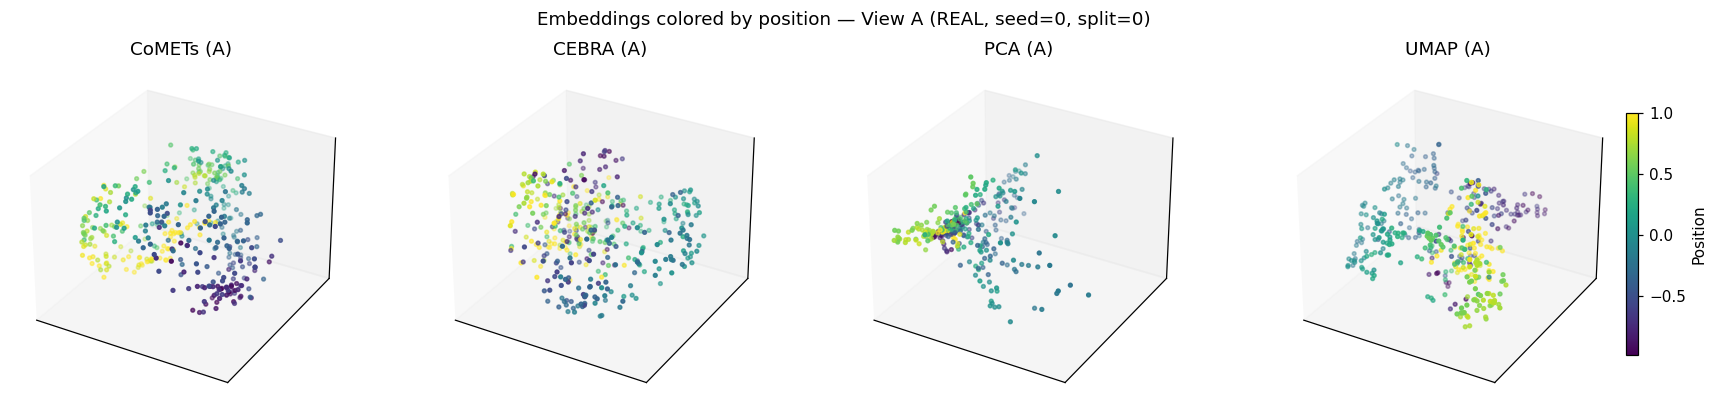

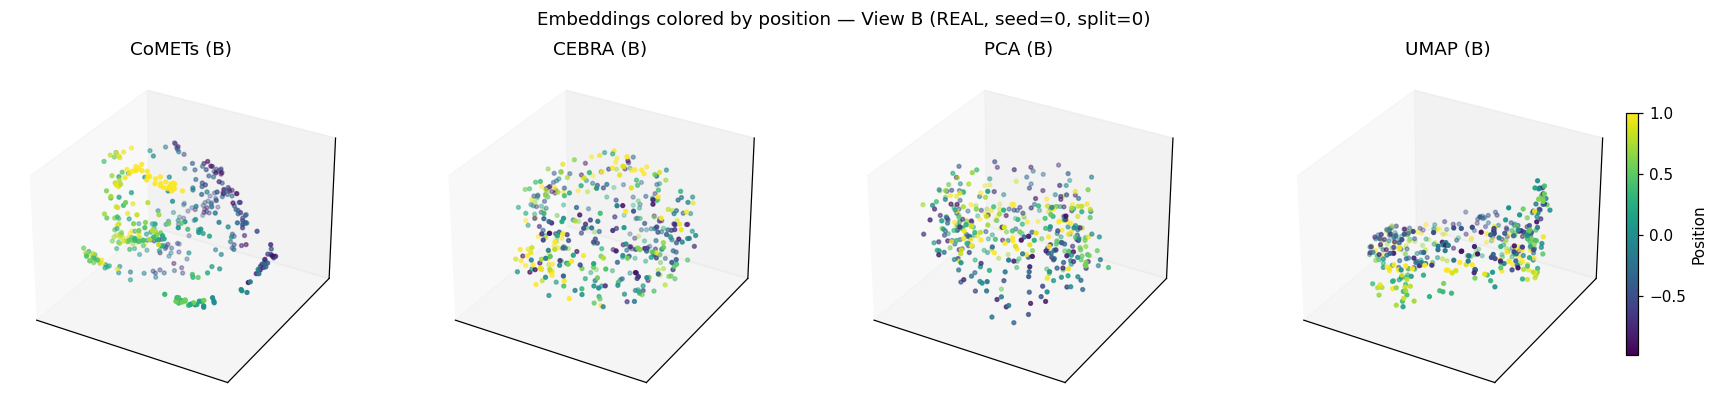

In [44]:
# =========================
# 8) Embedding visualization
# =========================
def plot_embedding_panel(EMB_SAMPLES, view="A"):
    # order in a row
    order = ["CoMETs","CEBRA","PCA","UMAP"]
    fig = plt.figure(figsize=(16,3.8))
    for i, m in enumerate(order):
        ax = fig.add_subplot(1,4,i+1, projection="3d")
        Zc, col = EMB_SAMPLES.get((m, view), (None, None))
        if Zc is None:
            ax.set_title(f"{m} ({view})\n(n/a)"); ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])
            continue
        p = ax.scatter(Zc[:,0], Zc[:,1], Zc[:,2], c=col, s=6)
        ax.set_title(f"{m} ({view})"); ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])
        if i==3:
            cb = plt.colorbar(p, ax=ax, fraction=0.03, pad=0.02)
            cb.set_label("Position")
    plt.suptitle(f"Embeddings colored by position — View {view} (REAL, seed=0, split=0)")
    plt.tight_layout(); plt.show()

plot_embedding_panel(EMB_SAMPLES, view="A")
plot_embedding_panel(EMB_SAMPLES, view="B")


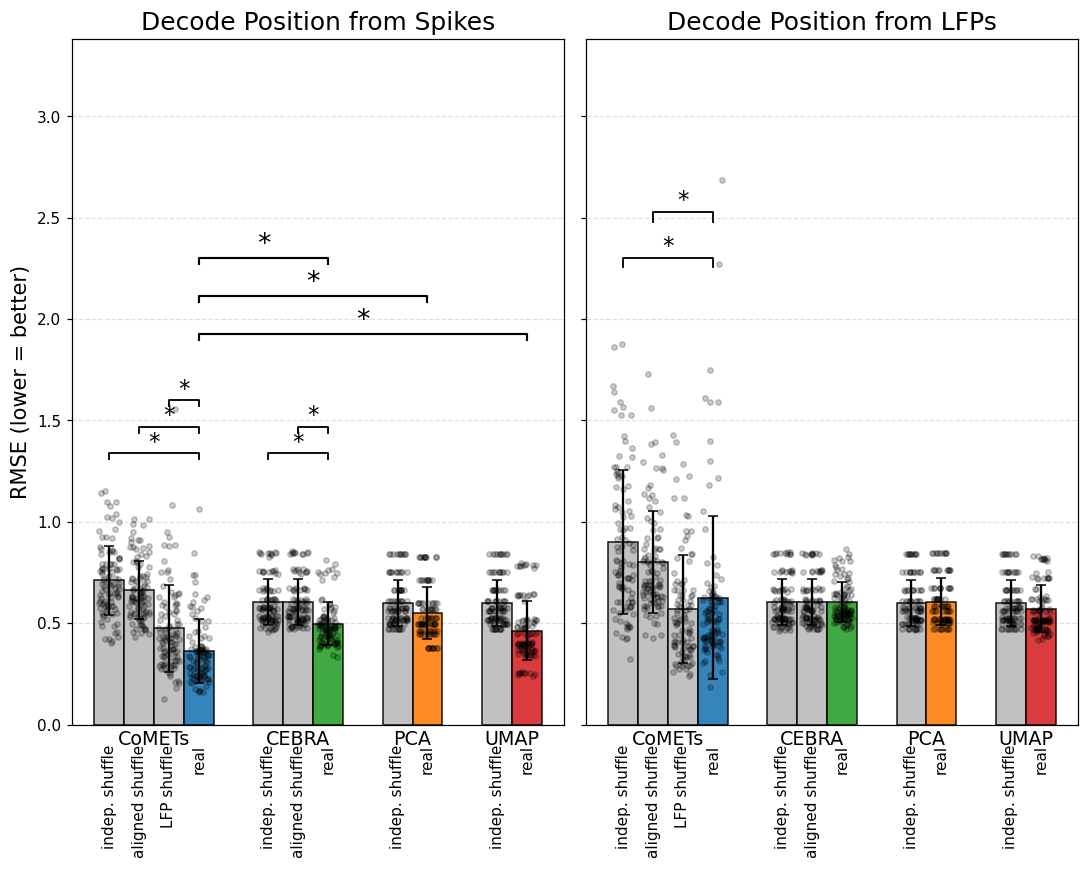

In [47]:
# === Shared plotting parameters ===
bar_width = 0.15
group_gap = 0.2
model_order = ["CoMETs", "CEBRA", "PCA", "UMAP"]
within_model_order = {
    "CoMETs": ["CoMETs_within", "CoMETs_temporal", "CoMETs_lfp", "CoMETs_real"],
    "CEBRA":  ["CEBRA_within", "CEBRA_temporal", "CEBRA_real"],
    "PCA":    ["PCA_within", "PCA_real"],
    "UMAP":   ["UMAP_within", "UMAP_real"],
}
model_colors = dict(CoMETs="tab:blue", CEBRA="tab:green", PCA="tab:orange", UMAP="tab:red")
asterisk_offset = 0.02
bracket_offset  = 0.015
font_scale = 1.25

# === Helper to prepare a view's stats ===
def prep_view(df_results, view):
    dfv = df_results[df_results["view"]==view].copy()
    name_map = {
        ("CoMETs","real"):          ("CoMETs_real","CoMETs","real"),
        ("CoMETs","channel_indep"): ("CoMETs_within","CoMETs","indep. shuffle"),
        ("CoMETs","global"):        ("CoMETs_temporal","CoMETs","aligned shuffle"),
        ("CoMETs","lfp_only"):      ("CoMETs_lfp","CoMETs","LFP shuffle"),

        ("CEBRA","real"):          ("CEBRA_real","CEBRA","real"),
        ("CEBRA","channel_indep"): ("CEBRA_within","CEBRA","indep. shuffle"),
        ("CEBRA","global"):        ("CEBRA_temporal","CEBRA","aligned shuffle"),

        ("PCA","real"):            ("PCA_real","PCA","real"),
        ("PCA","channel_indep"):   ("PCA_within","PCA","indep. shuffle"),

        ("UMAP","real"):           ("UMAP_real","UMAP","real"),
        ("UMAP","channel_indep"):  ("UMAP_within","UMAP","indep. shuffle"),
    }
    dfv["cond"] = dfv.apply(lambda r: name_map.get((r["model"],r["shuffle"]), (None,None,None))[0], axis=1)
    dfv["model_group"] = dfv.apply(lambda r: name_map.get((r["model"],r["shuffle"]), (None,None,None))[1], axis=1)
    dfv["shuffle_label"] = dfv.apply(lambda r: name_map.get((r["model"],r["shuffle"]), (None,None,None))[2], axis=1)
    dfv = dfv.dropna(subset=["cond"])
    stats = (dfv.groupby(["cond","model_group","shuffle_label"])
             .agg(mean_rmse=("rmse","mean"), std_rmse=("rmse","std"))
             .reset_index())
    return dfv, stats

# === Build both views ===
dfA, statsA = prep_view(df_results, "A")
dfB, statsB = prep_view(df_results, "B")

# === Make figure with two panels ===
fig, axes = plt.subplots(1, 2, figsize=(10, 8), sharey=True)
views = [("Decode Position from Spikes", dfA, statsA, axes[0]),
         ("Decode Position from LFPs",   dfB, statsB, axes[1])]

for title, dfv, stats, ax in views:
    xpos, colors, conds, labels_under = [], [], [], []
    current_x = 0
    for m in model_order:
        cond_list = within_model_order[m]
        for j, c in enumerate(cond_list):
            if c not in stats["cond"].values: continue
            xpos.append(current_x + j*bar_width)
            conds.append(c)
            labels_under.append(stats.loc[stats["cond"]==c, "shuffle_label"].values[0])
            colors.append(model_colors[m] if c.endswith("_real") else "#BBBBBB")
        current_x += len(cond_list)*bar_width + group_gap

    ymax = dfv["rmse"].max()*1.2
    for i,c in enumerate(conds):
        row = stats.loc[stats["cond"]==c].iloc[0]
        mean,std = row["mean_rmse"], row["std_rmse"]
        color = colors[i]
        ax.bar(xpos[i], mean, yerr=std, capsize=3, width=bar_width,
               color=color, edgecolor="black", alpha=0.9, zorder=2)
        vals = dfv[dfv["cond"]==c]["rmse"].values
        jitter = np.random.uniform(-bar_width/3, bar_width/3, len(vals))
        ax.scatter(np.full_like(vals, xpos[i])+jitter, vals,
                   s=10*font_scale, color="black", alpha=0.2, zorder=5)
        ax.text(xpos[i], -0.1, labels_under[i],
                ha="center", va="top", fontsize=8*font_scale, rotation=90)

    # Model labels
    centers = []
    for m in model_order:
        these = [x for c,x in zip(conds,xpos) if c.startswith(m)]
        centers.append(np.mean(these))
    ax.set_xticks(centers)
    ax.set_xticklabels(model_order, fontsize=10*font_scale)
    ax.set_ylim(0, 1.05*ymax)
    ax.set_title(title, fontsize=13*font_scale)
    ax.tick_params(axis='x', length=0)
    ax.grid(axis='y', linestyle='--', alpha=0.4)

    # ---- Within-model significance as low brackets (for CoMETs & CEBRA) ----
    for m in ["CoMETs", "CEBRA"]:
        real_cond = f"{m}_real"
        if real_cond not in dfv["cond"].values:
            continue
        real_vals = dfv[dfv["cond"] == real_cond].sort_values(["split"])["rmse"].values
        base_x = xpos[conds.index(real_cond)]
        
        # start lower than top brackets
        base_y = ymax * 0.70  
        offset_step = 0.07 * ymax  # vertical offset between multiple shuffles

        for sh_cond in [c for c in within_model_order[m] if "real" not in c]:
            if sh_cond not in dfv["cond"].values:
                continue
            sh_vals = dfv[dfv["cond"] == sh_cond].sort_values(["split"])["rmse"].values
            n = min(len(real_vals), len(sh_vals))
            if n >= 2:
                _, p = ttest_rel(real_vals[:n], sh_vals[:n])
                if p < 0.05:
                    x2 = xpos[conds.index(sh_cond)]
                    # draw small horizontal bracket
                    ax.plot([base_x, base_x, x2, x2],
                            [base_y, base_y + bracket_offset*ymax,
                            base_y + bracket_offset*ymax, base_y],
                            lw=1.2, c="k")
                    ax.text((base_x + x2)/2, base_y + 1.01*bracket_offset*ymax, "*",
                            ha="center", va="bottom", fontsize=12*font_scale)
                    base_y += offset_step  # stack brackets slightly higher each time

    # ---- Between-model brackets (CoMETs_real vs others) ----
    base_vals = dfv[dfv["cond"]=="CoMETs_real"].sort_values(["split"])["rmse"].values
    if len(base_vals)>1:
        base_x = xpos[conds.index("CoMETs_real")]
        bracket_y = ymax*(1.2+bracket_offset*1)
        for m in ["CEBRA","PCA","UMAP"]:
            real_cond = f"{m}_real"
            if real_cond not in dfv["cond"].values: continue
            vals = dfv[dfv["cond"]==real_cond].sort_values(["split"])["rmse"].values
            n = min(len(base_vals), len(vals))
            if n>=2:
                _,p = ttest_rel(base_vals[:n], vals[:n])
                if p<0.05:
                    x2 = xpos[conds.index(real_cond)]
                    ax.plot([base_x, base_x, x2, x2],
                            [bracket_y, bracket_y+bracket_offset*ymax,
                             bracket_y+bracket_offset*ymax, bracket_y],
                            lw=1.4, c="k")
                    ax.text((base_x+x2)/2, bracket_y+1.1*bracket_offset*ymax, "*",
                            ha="center", va="bottom", fontsize=14*font_scale)
                    bracket_y -= 0.1*ymax

axes[0].set_ylabel("RMSE (lower = better)", fontsize=11*font_scale)
plt.tight_layout()
plt.show()
# plt.savefig("shuffle_summary_rmse_full.svg", format="svg", bbox_inches="tight", transparent=True)

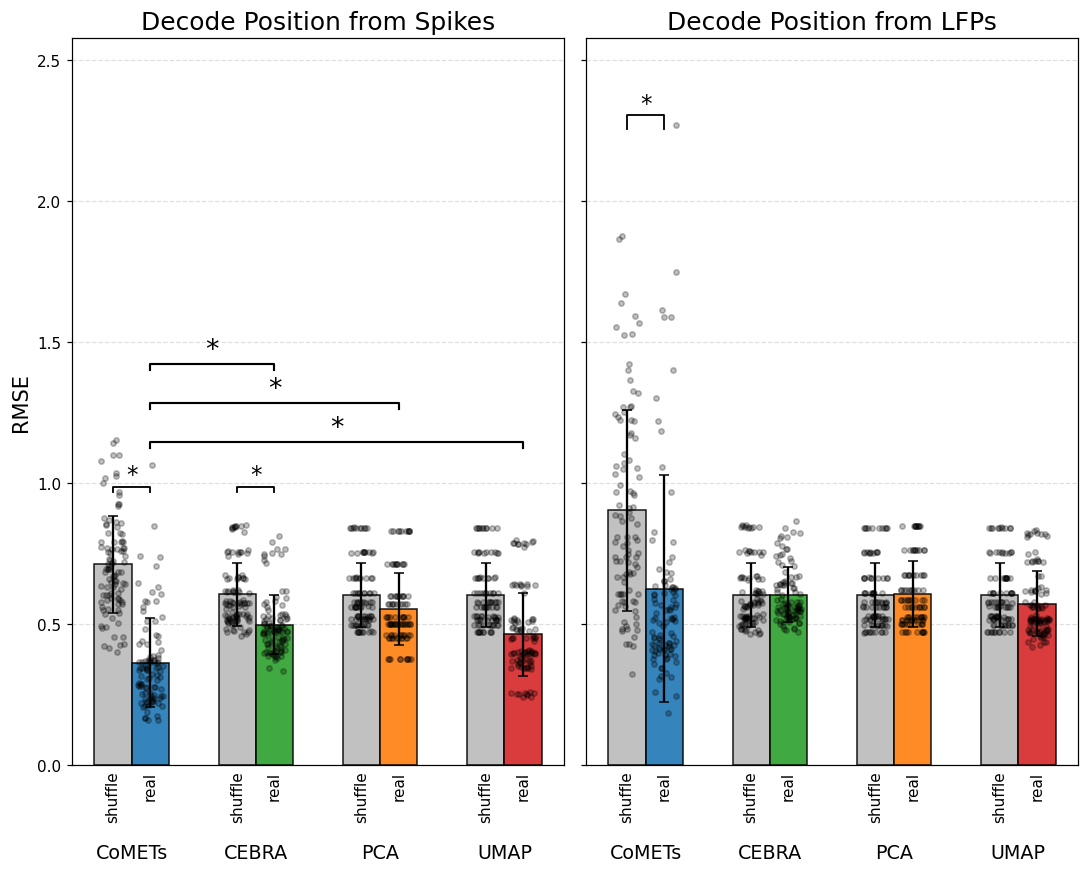

In [34]:
# === Shared plotting parameters ===
bar_width = 0.15
group_gap = 0.2
model_order = ["CoMETs", "CEBRA", "PCA", "UMAP"]
within_model_order = {
    "CoMETs": ["CoMETs_within", "CoMETs_real"],
    "CEBRA":  ["CEBRA_within", "CEBRA_real"],
    "PCA":    ["PCA_within", "PCA_real"],
    "UMAP":   ["UMAP_within", "UMAP_real"],
}
model_colors = dict(CoMETs="tab:blue", CEBRA="tab:green", PCA="tab:orange", UMAP="tab:red")
asterisk_offset = 0.02
bracket_offset  = 0.015
font_scale = 1.25

# === Helper to prepare a view's stats ===
def prep_view(df_results, view):
    dfv = df_results[df_results["view"]==view].copy()
    name_map = {
        ("CoMETs","real"):          ("CoMETs_real","CoMETs","real"),
        ("CoMETs","channel_indep"): ("CoMETs_within","CoMETs","shuffle"),

        ("CEBRA","real"):          ("CEBRA_real","CEBRA","real"),
        ("CEBRA","channel_indep"): ("CEBRA_within","CEBRA","shuffle"),

        ("PCA","real"):            ("PCA_real","PCA","real"),
        ("PCA","channel_indep"):   ("PCA_within","PCA","shuffle"),

        ("UMAP","real"):           ("UMAP_real","UMAP","real"),
        ("UMAP","channel_indep"):  ("UMAP_within","UMAP","shuffle"),
    }
    dfv["cond"] = dfv.apply(lambda r: name_map.get((r["model"],r["shuffle"]), (None,None,None))[0], axis=1)
    dfv["model_group"] = dfv.apply(lambda r: name_map.get((r["model"],r["shuffle"]), (None,None,None))[1], axis=1)
    dfv["shuffle_label"] = dfv.apply(lambda r: name_map.get((r["model"],r["shuffle"]), (None,None,None))[2], axis=1)
    dfv = dfv.dropna(subset=["cond"])
    stats = (dfv.groupby(["cond","model_group","shuffle_label"])
             .agg(mean_rmse=("rmse","mean"), std_rmse=("rmse","std"))
             .reset_index())
    return dfv, stats

# === Build both views ===
dfA, statsA = prep_view(df_results, "A")
dfB, statsB = prep_view(df_results, "B")

# === Make figure with two panels ===
fig, axes = plt.subplots(1, 2, figsize=(10, 8), sharey=True)
views = [("Decode Position from Spikes", dfA, statsA, axes[0]),
         ("Decode Position from LFPs",   dfB, statsB, axes[1])]

for title, dfv, stats, ax in views:
    xpos, colors, conds, labels_under = [], [], [], []
    current_x = 0
    for m in model_order:
        cond_list = within_model_order[m]
        for j, c in enumerate(cond_list):
            if c not in stats["cond"].values: continue
            xpos.append(current_x + j*bar_width)
            conds.append(c)
            labels_under.append(stats.loc[stats["cond"]==c, "shuffle_label"].values[0])
            colors.append(model_colors[m] if c.endswith("_real") else "#BBBBBB")
        current_x += len(cond_list)*bar_width + group_gap

    ymax = dfv["rmse"].max() * 1.2

    for i, c in enumerate(conds):
        row = stats.loc[stats["cond"] == c].iloc[0]
        mean, std = row["mean_rmse"], row["std_rmse"]
        color = colors[i]
        ax.bar(xpos[i], mean, yerr=std, capsize=3, width=bar_width,
            color=color, edgecolor="black", alpha=0.9, zorder=2)

        # scatter points (individual RMSE values)
        vals = dfv[dfv["cond"] == c]["rmse"].values
        jitter = np.random.uniform(-bar_width / 3, bar_width / 3, len(vals))
        ax.scatter(np.full_like(vals, xpos[i]) + jitter, vals,
                s=10 * font_scale, color="black", alpha=0.25, zorder=5)

        # label for each condition (real/shuffle type)
        ax.text(xpos[i], -0.02, labels_under[i],
                ha="center", va="top", fontsize=8 * font_scale, rotation=90)

    # === Model group centers ===
    centers = []
    for m in model_order:
        these = [x for c, x in zip(conds, xpos) if c.startswith(m)]
        if these:
            centers.append(np.mean(these))
        else:
            centers.append(np.nan)

    # === Lower the model labels ===
    ax.set_xticks(centers)
    ax.set_xticklabels(model_order, fontsize=10 * font_scale, y= -0.1)  # 

    # # alternatively, for matplotlib <3.5, use this workaround:
    # for label in ax.get_xticklabels():
    #     label.set_y(-0.07)  # push labels downward

    # === Aesthetics ===
    ax.set_ylim(0, 0.8 * ymax)
    ax.set_title(title, fontsize=13 * font_scale)
    ax.tick_params(axis="x", length=0)
    ax.grid(axis="y", linestyle="--", alpha=0.4)


    # ---- Within-model significance as low brackets (for CoMETs & CEBRA) ----
    for m in ["CoMETs", "CEBRA"]:
        real_cond = f"{m}_real"
        if real_cond not in dfv["cond"].values:
            continue
        real_vals = dfv[dfv["cond"] == real_cond].sort_values(["split"])["rmse"].values
        base_x = xpos[conds.index(real_cond)]
        
        # start lower than top brackets
        base_y = ymax * 0.70  
        offset_step = 0.07 * ymax  # vertical offset between multiple shuffles

        for sh_cond in [c for c in within_model_order[m] if "real" not in c]:
            if sh_cond not in dfv["cond"].values:
                continue
            sh_vals = dfv[dfv["cond"] == sh_cond].sort_values(["split"])["rmse"].values
            n = min(len(real_vals), len(sh_vals))
            if n >= 2:
                _, p = ttest_rel(real_vals[:n], sh_vals[:n])
                if p < 0.05:
                    x2 = xpos[conds.index(sh_cond)]
                    # draw small horizontal bracket
                    ax.plot([base_x, base_x, x2, x2],
                            [base_y, base_y + bracket_offset*ymax,
                            base_y + bracket_offset*ymax, base_y],
                            lw=1.2, c="k")
                    ax.text((base_x + x2)/2, base_y + 1.01*bracket_offset*ymax, "*",
                            ha="center", va="bottom", fontsize=12*font_scale)
                    base_y += offset_step  # stack brackets slightly higher each time

    # ---- Between-model brackets (CoMETs_real vs others) ----
    base_vals = dfv[dfv["cond"]=="CoMETs_real"].sort_values(["split"])["rmse"].values
    if len(base_vals)>1:
        base_x = xpos[conds.index("CoMETs_real")]
        bracket_y = ymax*(1+bracket_offset*1)
        for m in ["CEBRA","PCA","UMAP"]:
            real_cond = f"{m}_real"
            if real_cond not in dfv["cond"].values: continue
            vals = dfv[dfv["cond"]==real_cond].sort_values(["split"])["rmse"].values
            n = min(len(base_vals), len(vals))
            if n>=2:
                _,p = ttest_rel(base_vals[:n], vals[:n])
                if p<0.05:
                    x2 = xpos[conds.index(real_cond)]
                    ax.plot([base_x, base_x, x2, x2],
                            [bracket_y, bracket_y+bracket_offset*ymax,
                             bracket_y+bracket_offset*ymax, bracket_y],
                            lw=1.4, c="k")
                    ax.text((base_x+x2)/2, bracket_y+1.1*bracket_offset*ymax, "*",
                            ha="center", va="bottom", fontsize=14*font_scale)
                    bracket_y -= 0.1*ymax

axes[0].set_ylabel("RMSE", fontsize=11*font_scale)
plt.tight_layout()
plt.show()

# plt.savefig("shuffle_summary_rmse.svg", format="svg", bbox_inches="tight", transparent=True)

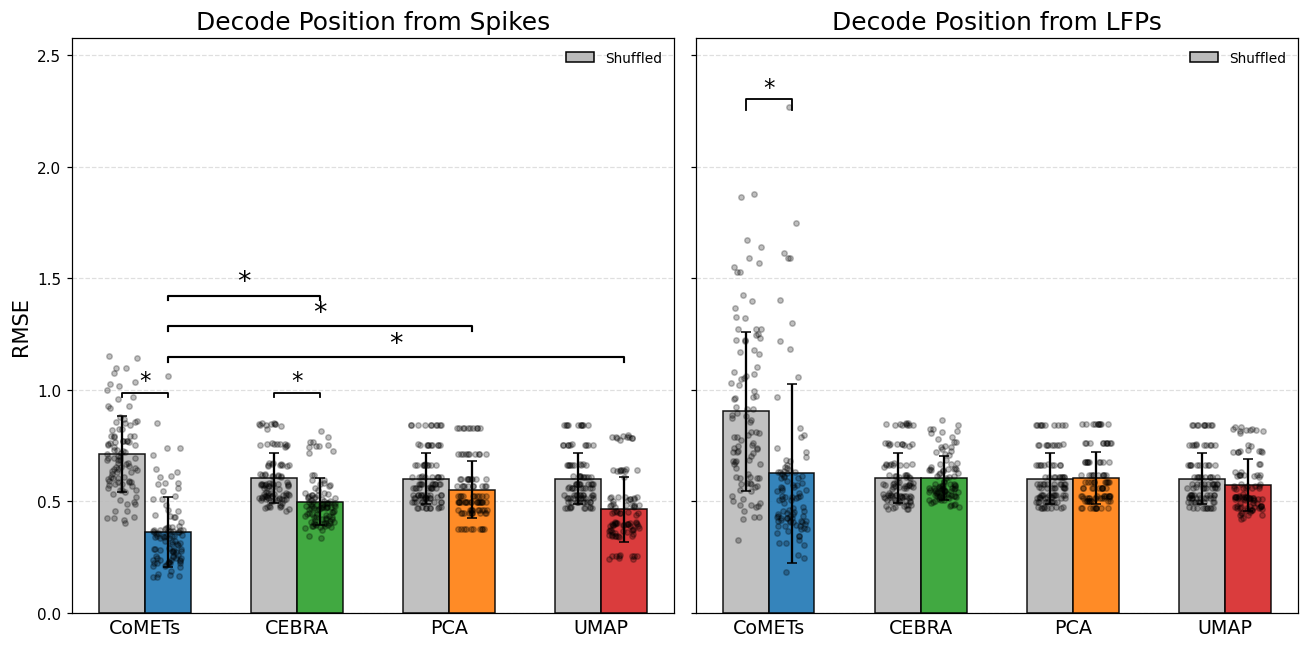

<Figure size 704x528 with 0 Axes>

In [ ]:
# === Shared plotting parameters ===
bar_width = 0.15
group_gap = 0.2
model_order = ["CoMETs", "CEBRA", "PCA", "UMAP"]
within_model_order = {
    "CoMETs": ["CoMETs_within", "CoMETs_real"],
    "CEBRA":  ["CEBRA_within", "CEBRA_real"],
    "PCA":    ["PCA_within", "PCA_real"],
    "UMAP":   ["UMAP_within", "UMAP_real"],
}
model_colors = dict(CoMETs="tab:blue", CEBRA="tab:green", PCA="tab:orange", UMAP="tab:red")
asterisk_offset = 0.02
bracket_offset  = 0.015
font_scale = 1.25

# === Helper to prepare a view's stats ===
def prep_view(df_results, view):
    dfv = df_results[df_results["view"] == view].copy()
    name_map = {
        ("CoMETs","real"):          ("CoMETs_real","CoMETs","real"),
        ("CoMETs","channel_indep"): ("CoMETs_within","CoMETs","shuffle"),

        ("CEBRA","real"):          ("CEBRA_real","CEBRA","real"),
        ("CEBRA","channel_indep"): ("CEBRA_within","CEBRA","shuffle"),

        ("PCA","real"):            ("PCA_real","PCA","real"),
        ("PCA","channel_indep"):   ("PCA_within","PCA","shuffle"),

        ("UMAP","real"):           ("UMAP_real","UMAP","real"),
        ("UMAP","channel_indep"):  ("UMAP_within","UMAP","shuffle"),
    }
    dfv["cond"] = dfv.apply(lambda r: name_map.get((r["model"],r["shuffle"]), (None,None,None))[0], axis=1)
    dfv["model_group"] = dfv.apply(lambda r: name_map.get((r["model"],r["shuffle"]), (None,None,None))[1], axis=1)
    dfv["shuffle_label"] = dfv.apply(lambda r: name_map.get((r["model"],r["shuffle"]), (None,None,None))[2], axis=1)
    dfv = dfv.dropna(subset=["cond"])
    stats = (
        dfv.groupby(["cond", "model_group", "shuffle_label"])
        .agg(mean_rmse=("rmse", "mean"), std_rmse=("rmse", "std"))
        .reset_index()
    )
    return dfv, stats


# === Build both views ===
dfA, statsA = prep_view(df_results, "A")
dfB, statsB = prep_view(df_results, "B")

# === Make figure with two panels ===
fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharey=True)
views = [("Decode Position from Spikes", dfA, statsA, axes[0]),
         ("Decode Position from LFPs",   dfB, statsB, axes[1])]

for title, dfv, stats, ax in views:
    xpos, colors, conds = [], [], []
    current_x = 0
    for m in model_order:
        cond_list = within_model_order[m]
        for j, c in enumerate(cond_list):
            if c not in stats["cond"].values:
                continue
            xpos.append(current_x + j * bar_width)
            conds.append(c)
            colors.append(model_colors[m] if c.endswith("_real") else "#BBBBBB")
        current_x += len(cond_list) * bar_width + group_gap

    ymax = dfv["rmse"].max() * 1.2

    # === Plot bars and scatter points ===
    for i, c in enumerate(conds):
        row = stats.loc[stats["cond"] == c].iloc[0]
        mean, std = row["mean_rmse"], row["std_rmse"]
        color = colors[i]
        ax.bar(xpos[i], mean, yerr=std, capsize=3, width=bar_width,
               color=color, edgecolor="black", alpha=0.9, zorder=2)
        vals = dfv[dfv["cond"] == c]["rmse"].values
        jitter = np.random.uniform(-bar_width / 3, bar_width / 3, len(vals))
        ax.scatter(np.full_like(vals, xpos[i]) + jitter, vals,
                   s=10 * font_scale, color="black", alpha=0.25, zorder=5)

    # === Model group centers ===
    centers = []
    for m in model_order:
        these = [x for c, x in zip(conds, xpos) if c.startswith(m)]
        centers.append(np.mean(these) if these else np.nan)

    ax.set_xticks(centers)
    ax.set_xticklabels(model_order, fontsize=10 * font_scale)
    ax.tick_params(axis="x", length=0)
    ax.set_ylim(0, 0.8 * ymax)
    ax.set_title(title, fontsize=13 * font_scale)
    ax.grid(axis="y", linestyle="--", alpha=0.4)

    # === Legend (colored = Real, gray = Shuffled) ===
    from matplotlib.patches import Patch
    legend_elems = [
        Patch(facecolor="#BBBBBB", edgecolor='black', label='Shuffled')
    ]
    ax.legend(handles=legend_elems, loc='upper right', frameon=False, fontsize=9)

    # ---- Within-model significance (CoMETs & CEBRA) ----
    for m in ["CoMETs", "CEBRA"]:
        real_cond = f"{m}_real"
        if real_cond not in dfv["cond"].values:
            continue
        real_vals = dfv[dfv["cond"] == real_cond].sort_values(["split"])["rmse"].values
        base_x = xpos[conds.index(real_cond)]
        base_y = ymax * 0.70
        for sh_cond in [c for c in within_model_order[m] if "real" not in c]:
            if sh_cond not in dfv["cond"].values:
                continue
            sh_vals = dfv[dfv["cond"] == sh_cond].sort_values(["split"])["rmse"].values
            n = min(len(real_vals), len(sh_vals))
            if n >= 2:
                _, p = ttest_rel(real_vals[:n], sh_vals[:n])
                if p < 0.05:
                    x2 = xpos[conds.index(sh_cond)]
                    ax.plot([base_x, base_x, x2, x2],
                            [base_y, base_y + bracket_offset * ymax,
                             base_y + bracket_offset * ymax, base_y],
                            lw=1.2, c="k")
                    ax.text((base_x + x2) / 2, base_y + 1.01 * bracket_offset * ymax, "*",
                            ha="center", va="bottom", fontsize=12 * font_scale)
                    base_y += 0.07 * ymax

    # ---- Between-model brackets (CoMETs_real vs others) ----
    base_vals = dfv[dfv["cond"] == "CoMETs_real"].sort_values(["split"])["rmse"].values
    if len(base_vals) > 1:
        base_x = xpos[conds.index("CoMETs_real")]
        bracket_y = ymax * (1 + bracket_offset * 1)
        for m in ["CEBRA", "PCA", "UMAP"]:
            real_cond = f"{m}_real"
            if real_cond not in dfv["cond"].values:
                continue
            vals = dfv[dfv["cond"] == real_cond].sort_values(["split"])["rmse"].values
            n = min(len(base_vals), len(vals))
            if n >= 2:
                _, p = ttest_rel(base_vals[:n], vals[:n])
                if p < 0.05:
                    x2 = xpos[conds.index(real_cond)]
                    ax.plot([base_x, base_x, x2, x2],
                            [bracket_y, bracket_y + bracket_offset * ymax,
                             bracket_y + bracket_offset * ymax, bracket_y],
                            lw=1.4, c="k")
                    ax.text((base_x + x2) / 2, bracket_y + 1.1 * bracket_offset * ymax, "*",
                            ha="center", va="bottom", fontsize=14 * font_scale)
                    bracket_y -= 0.1 * ymax

axes[0].set_ylabel("RMSE", fontsize=11 * font_scale)
plt.tight_layout()
plt.show()
# plt.savefig("shuffle_summary_rmse.svg", format="svg", bbox_inches="tight", transparent=True)


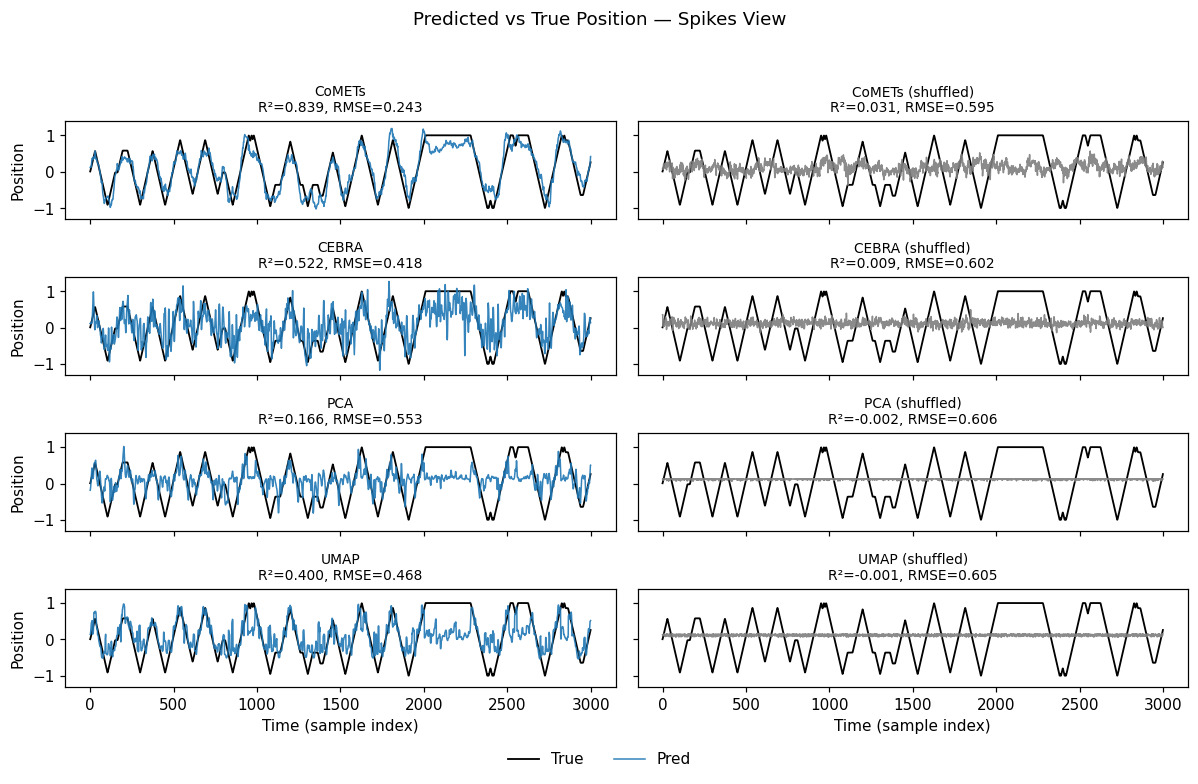

In [45]:
# ============================================================
# Predicted vs True Position — Real vs Shuffled (clean naming)
# ============================================================

Nshow = 3000  # number of samples to visualize
view  = "A"   # "A" = spikes, "B" = LFPs
models_to_plot = ["CoMETs", "CEBRA", "PCA", "UMAP"]
shuffle_modes  = ["real", "channel_indep"]  # real vs shuffled

def rmse(y, yhat):
    return np.sqrt(np.mean((y - yhat) ** 2))

fig, axes = plt.subplots(len(models_to_plot), len(shuffle_modes),
                         figsize=(11, 7), sharex=True, sharey=True)

if len(models_to_plot) == 1:
    axes = np.expand_dims(axes, 0)

for i, model in enumerate(models_to_plot):
    for j, shuffle_mode in enumerate(shuffle_modes):
        ax = axes[i, j]
        key = (model, view, shuffle_mode)
        rec = TRAJ_EXAMPLE.get(key, None)

        if rec is None:
            ax.text(0.5, 0.5, f"No record for {model}\n({shuffle_mode})",
                    ha="center", va="center", fontsize=9)
            ax.axis("off")
            continue

        yhat_full = rec["y_pred_full"]
        ytrue_full = position_real
        n = min(Nshow, len(ytrue_full))

        # compute metrics on visible range
        r2 = r2_score(ytrue_full[:n], yhat_full[:n])
        e  = rmse(ytrue_full[:n], yhat_full[:n])

        # clean label naming
        title_name = f"{model}" if shuffle_mode == "real" else f"{model} (shuffled)"

        # plot
        ax.plot(ytrue_full[:n], color="black", lw=1.2, label="True")
        ax.plot(yhat_full[:n],
                color=("tab:blue" if shuffle_mode == "real" else "tab:gray"),
                lw=1.0, alpha=0.9, label="Pred")
        ax.set_title(f"{title_name}\nR²={r2:.3f}, RMSE={e:.3f}", fontsize=9)
        if i == len(models_to_plot) - 1:
            ax.set_xlabel("Time (sample index)")
        if j == 0:
            ax.set_ylabel("Position")

# unified legend at bottom (non-overlapping)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=2,
           frameon=False, bbox_to_anchor=(0.5, -0.02))

fig.suptitle(f"Predicted vs True Position — {('Spikes' if view=='A' else 'LFPs')} View",
             fontsize=12, y=0.98)

plt.tight_layout(rect=[0, 0.02, 1, 0.95])
plt.show()

# # # Save figure
# plt.savefig(f"pred_vs_true_{view.lower()}_shuffled.svg", format="svg", bbox_inches="tight", transparent=True)


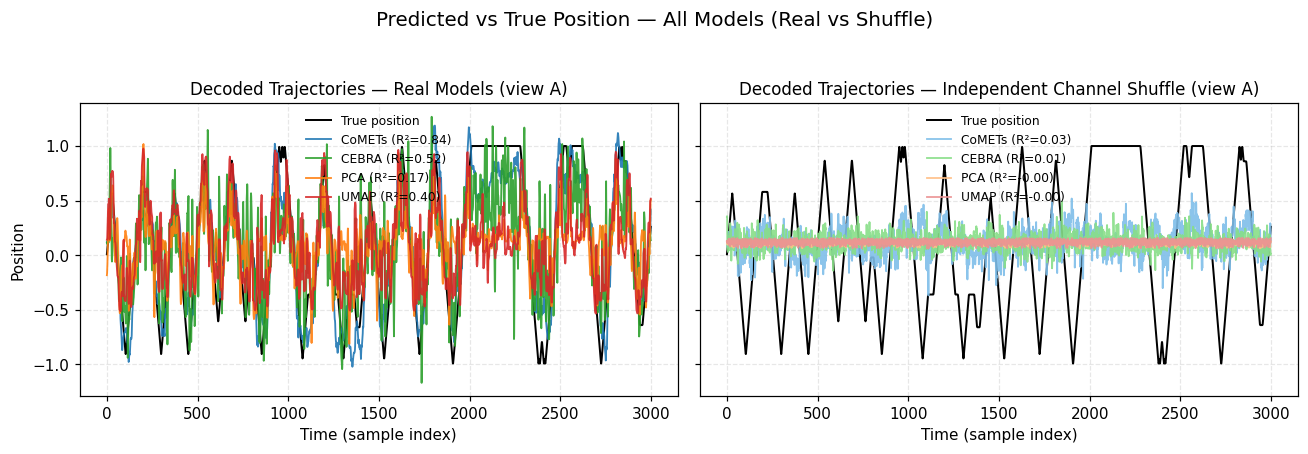

In [19]:
# ============================================================
# Combined Predicted Trajectories — Real vs Channel-Independent Shuffle
# ============================================================

Nshow = 3000   # number of samples to show
view  = "A"    # "A" = spikes, "B" = LFPs
models_to_plot = ["CoMETs", "CEBRA", "PCA", "UMAP"]

# use your consistent color scheme
model_colors = dict(CoMETs="tab:blue", CEBRA="tab:green", PCA="tab:orange", UMAP="tab:red")

def lighten_color(color, amount=0.5):
    """Return a lighter version of the given matplotlib color."""
    import matplotlib.colors as mc, colorsys
    try:
        c = mc.cnames[color]
    except KeyError:
        c = color
    h, l, s = colorsys.rgb_to_hls(*mc.to_rgb(c))
    return colorsys.hls_to_rgb(h, 1 - amount*(1 - l), s)

def rmse(y, yhat): 
    return np.sqrt(np.mean((y - yhat) ** 2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True, sharey=True)
ax_real, ax_shuf = axes

ytrue = position_real
ax_real.plot(ytrue[:Nshow], color="black", lw=1.3, label="True position")

# ---------------- LEFT: Real models ----------------
for model in models_to_plot:
    key = (model, view, "real")
    rec = TRAJ_EXAMPLE.get(key, None)
    if rec is None:
        continue
    yhat = rec["y_pred_full"][:Nshow]
    r2 = r2_score(ytrue[:Nshow], yhat)
    e  = rmse(ytrue[:Nshow], yhat)
    ax_real.plot(yhat, color=model_colors[model], lw=1.2, alpha=0.9,
                 label=f"{model} (R²={r2:.2f})")

ax_real.set_title(f"Decoded Trajectories — Real Models (view {view})", fontsize=11)
ax_real.set_xlabel("Time (sample index)")
ax_real.set_ylabel("Position")
ax_real.legend(frameon=False, fontsize=8)
ax_real.grid(alpha=0.3, linestyle="--")

# ---------------- RIGHT: Independent-channel shuffle ----------------
ax_shuf.plot(ytrue[:Nshow], color="black", lw=1.3, label="True position")

for model in models_to_plot:
    key = (model, view, "channel_indep")
    rec = TRAJ_EXAMPLE.get(key, None)
    if rec is None:
        continue
    yhat = rec["y_pred_full"][:Nshow]
    r2 = r2_score(ytrue[:Nshow], yhat)
    e  = rmse(ytrue[:Nshow], yhat)
    ax_shuf.plot(yhat, color=lighten_color(model_colors[model], 0.5),
                 lw=1.2, alpha=0.9,
                 label=f"{model} (R²={r2:.2f})")

ax_shuf.set_title(f"Decoded Trajectories — Independent Channel Shuffle (view {view})", fontsize=11)
ax_shuf.set_xlabel("Time (sample index)")
ax_shuf.legend(frameon=False, fontsize=8)
ax_shuf.grid(alpha=0.3, linestyle="--")

plt.suptitle("Predicted vs True Position — All Models (Real vs Shuffle)", fontsize=13, y=1.02)
plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.show()
